Adding imports

In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import json

from pathlib import Path
from PIL import Image

from torchvision import transforms
from torchvision.models import (
    densenet121)

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    accuracy_score)

import matplotlib.pyplot as plt

Load the saved model files

In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu")

MODEL_DIR = Path("/home/vsarasani/Ray-Verify-/saved_models")

print("Device:", device)
print("Model directory:", MODEL_DIR.resolve())

Device: cuda
Model directory: /home/vsarasani/Ray-Verify-/saved_models


Loading the test data

In [7]:
test_manifest = pd.read_csv(
    MODEL_DIR / "test_manifest.csv")

test_paths = test_manifest["path"].tolist()
test_labels = test_manifest["label"].to_numpy()

print("Total test images:", len(test_paths))
print("Patient-acquired:", (test_labels == 0).sum())
print("Synthetic:", (test_labels == 1).sum())

Total test images: 2521
Patient-acquired: 1264
Synthetic: 1257


Preprocessing code 

In [8]:
from torchvision.models import DenseNet121_Weights

densenet_weights = DenseNet121_Weights.DEFAULT

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    densenet_weights.transforms()
])

print("DenseNet-121 preprocessing loaded.")

DenseNet-121 preprocessing loaded.


In [9]:
class XrayDataset(Dataset):

    def __init__(self, paths, labels, transform):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        with Image.open(self.paths[index]) as img:
            image = self.transform(img.convert("L"))

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return image, label

Creating a dataloader

In [10]:
test_dataset = XrayDataset(
    test_paths,
    test_labels,
    transform=eval_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0)

print("Test loader ready:", len(test_dataset))

Test loader ready: 2521


Load DenseNet-121 ensemble

In [11]:
densenet_checkpoint = torch.load(
    MODEL_DIR / "densenet121_ensemble.pkl",
    map_location="cpu",
    weights_only=True)

densenet_models = []

for state_dict in densenet_checkpoint["fold_models"]:

    model = densenet121(weights=None)

    model.classifier = nn.Linear(
        model.classifier.in_features,
        2)

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()

    densenet_models.append(model)

print("DenseNet models loaded:", len(densenet_models))

DenseNet models loaded: 5


Test DenseNet-121

In [12]:
# Test DenseNet-121 ensemble

densenet_probability_sum = np.zeros(
    (len(test_dataset), 2),
    dtype=np.float64)

for model in densenet_models:

    model.eval()
    predictions = []

    with torch.no_grad():

        for images, _ in test_loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            predictions.extend(
                probabilities.cpu().numpy() )

    densenet_probability_sum += np.asarray(predictions)


# Average probabilities from all five models
densenet_probabilities = (
    densenet_probability_sum / len(densenet_models))

# Get predictions and confidence scores
densenet_predictions = densenet_probabilities.argmax(axis=1)

densenet_scores = densenet_probabilities.max(axis=1)


# Apply uncertainty threshold
TEST_THRESHOLD = 0.80

densenet_final = np.where(
    densenet_scores < TEST_THRESHOLD,
    -1,
    densenet_predictions)

print("DenseNet testing completed!")
print("Number of test images:", len(test_dataset))
print("Number of uncertain images:", np.sum(densenet_final == -1))
print("Number of classified images:", np.sum(densenet_final != -1))

DenseNet testing completed!
Number of test images: 2521
Number of uncertain images: 59
Number of classified images: 2462


Calculate DenseNet test metrics

In [13]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix)

# Ground-truth labels from the original test manifest
actual_labels = np.asarray(test_labels, dtype=int)

def test_metrics(actual, final):

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        final,
        labels=[0, 1],
        zero_division=0  )

    classified = final != -1

    return {
        "Synthetic precision": precision[1],
        "Synthetic recall": recall[1],
        "Synthetic F1": f1[1],

        "Patient-acquired precision": precision[0],
        "Patient-acquired recall": recall[0],
        "Patient-acquired F1": f1[0],

        "Coverage": classified.mean(),

        "Error among classified": (
            (final[classified] != actual[classified]).mean()
            if classified.any() else np.nan
        ),

        "Uncertain images": int((~classified).sum()) }


densenet_test_results = test_metrics(
    actual_labels,
    densenet_final)

densenet_test_table = pd.DataFrame(
    [densenet_test_results],
    index=["DenseNet-121 ensemble"])

display(
    densenet_test_table.style.format({
        column: "{:.2%}"
        for column in densenet_test_table.columns
        if column != "Uncertain images" }).format({ "Uncertain images": "{:.0f}"}))

,Synthetic precision,Synthetic recall,Synthetic F1,Patient-acquired precision,Patient-acquired recall,Patient-acquired F1,Coverage,Error among classified,Uncertain images
DenseNet-121 ensemble,0.995078,0.964996,0.979806,0.995173,0.978639,0.986837,0.976597,0.004874,59


Confusion matrix including uncertain predictions

In [14]:
labels = [0, 1]

cm = confusion_matrix(
    actual_labels,
    densenet_final,
    labels=labels)

print("Confusion matrix for classified images:")
display(pd.DataFrame(
    cm,
    index=["Actual Patient-acquired", "Actual Synthetic"],
    columns=["Predicted Patient-acquired", "Predicted Synthetic"]))

print("Uncertain predictions:", np.sum(densenet_final == -1))

Confusion matrix for classified images:


,Predicted Patient-acquired,Predicted Synthetic
Actual Patient-acquired,1237,6
Actual Synthetic,6,1213


Uncertain predictions: 59


Save DenseNet test predictions

In [15]:
from pathlib import Path
import json

# Use a dedicated output directory
TEST_OUTPUT_DIR = Path("testing_results")
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

names = {
    -1: "Uncertain",
    0: "Patient-acquired",
    1: "Synthetic"}

densenet_test_predictions = pd.DataFrame({
    "path": test_paths,
    "true_label": actual_labels,

    "patient_acquired_score": densenet_probabilities[:, 0],
    "synthetic_score": densenet_probabilities[:, 1],

    "binary_prediction": densenet_predictions,
    "model_score": densenet_scores,

    "final_prediction": [
        names[int(p)] for p in densenet_final  ]})

densenet_test_predictions.to_csv(
    TEST_OUTPUT_DIR / "densenet_test_predictions.csv",
    index=False)

densenet_test_table.to_csv(
    TEST_OUTPUT_DIR / "densenet_test_metrics.csv")

# Save evaluation configuration
(TEST_OUTPUT_DIR / "test_evaluation_config.json").write_text(
    json.dumps({
        "model": "DenseNet-121",
        "ensemble_models": len(densenet_models),
        "threshold": TEST_THRESHOLD,
        "test_images": len(actual_labels),
        "ensemble_method": "Equal average of five models' softmax probabilities",
        "uncertainty_label": -1
    }, indent=2))

print("DenseNet test results saved in:", TEST_OUTPUT_DIR)

DenseNet test results saved in: testing_results


**Human Computer Interface** for densenet

Loading 5 densenet models

In [16]:
import gradio as gr
import torch

# Reuse the five DenseNet models already loaded
# in the Testing notebook

dn_ui_models = densenet_models

# Set all models to evaluation mode
for model in dn_ui_models:
    model.eval()

print("DenseNet HCI models ready:", len(dn_ui_models))

assert len(dn_ui_models) == 5, "Expected 5 DenseNet models"

DenseNet HCI models ready: 5


Defining action OF Densenet

In [17]:
def analyze_densenet(image):
    if image is None:
        return "Please upload an image first.", "", None, ""

    try:
        tensor = eval_transform(
            image.convert("L")).unsqueeze(0).to(device)

        with torch.no_grad():
            probabilities = torch.stack([
                torch.softmax(model(tensor), dim=1)
                for model in dn_ui_models ]).mean(dim=0)[0]

        patient_score, synthetic_score = probabilities.cpu().tolist()
        maximum_score = max(patient_score, synthetic_score)

        if maximum_score < 0.80:
            prediction = "Uncertain"
            guidance = (
                "Classification withheld. Check the image's source "
                "and provenance before deciding." )
        else:
            prediction = (
                "Patient-acquired"
                if patient_score >= synthetic_score
                else "Synthetic")
            guidance = (
                "Review the image's source and provenance. "
                "The model can still be incorrect." )

        scores = (
            f"Patient-acquired: {patient_score:.4f}\n"
            f"Synthetic: {synthetic_score:.4f}\n"
            f"Withholding threshold: 0.80\n\n"
            "Uncalibrated model scores—not probabilities of correctness.")

        return (
            f"## {prediction}\n\n{guidance}",
            scores,
            {"prediction": prediction},
            "")

    except Exception as error:
        print("DenseNet inference error:", repr(error))
        return (
            "Analysis failed. Try another readable image.",
            "",
            None,
            "" )


def record_densenet_decision(record, decision, notes):
    if record is None:
        return "Analyze an image before recording your decision."

    return (f"AI prediction: {record['prediction']}\n"
        f"Curator decision: {decision}\n"
        f"Notes: {notes.strip() or 'None'}\n\n"
        "This record is displayed for this session only.")


def reset_densenet():
    return (
        "## Ready to analyze",
        "",
        None,
        "Leave unresolved",
        "",
        "")

Launching interface

In [18]:
dn_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto;
}
#dn-header {
    background: linear-gradient(120deg, #17324d, #087f8c);
    padding: 26px;
    border-radius: 16px;
    margin-bottom: 18px;
}
#dn-header h1, #dn-header p {
    color: white !important;
}
"""

# Close an earlier DenseNet interface if this cell is rerun.
if "dn_demo" in globals():
    dn_demo.close()

with gr.Blocks(
    title="Ray Verify | DenseNet",
    theme=gr.themes.Soft(),
    css=dn_css,
    delete_cache=(3600, 3600)
) as dn_demo:

    gr.HTML("""
        <div id="dn-header">
            <h1>Ray Verify</h1>
            <p>Chest X-ray origin screening · DenseNet-121 ensemble</p>
        </div>
    """)

    gr.Markdown(
        "Upload a de-identified chest X-ray, review the prediction, "
        "and make your own decision. "
        "**Research prototype—not for medical diagnosis.**")

    dn_record = gr.State(None)

    with gr.Row():
        with gr.Column():
            dn_image = gr.Image(
                label="Upload chest X-ray",
                type="pil",
                sources=["upload"],
                height=350)

            with gr.Row():
                dn_analyze = gr.Button(
                    "Analyze image",
                    variant="primary" )
                dn_clear = gr.Button("Clear")

        with gr.Column():
            dn_result = gr.Markdown("## Ready to analyze")

            dn_scores_display = gr.Textbox(
                label="Average scores from five models",
                lines=6,
                interactive=False)

            gr.Markdown(
                "**Uncertain** means the highest average score "
                "is below 0.80. A higher score does not guarantee "
                "a correct prediction." )

    gr.Markdown("### Your review")
    gr.Markdown(
        "Your decision remains separate from the AI prediction. "
        "You can disagree with the model or leave the case unresolved.")

    dn_decision = gr.Radio(
        choices=[
            "Include in research dataset",
            "Exclude from research dataset",
            "Leave unresolved" ],
        value="Leave unresolved",
        label="Curator decision")

    dn_notes = gr.Textbox(
        label="Review notes",
        placeholder="Explain your decision or what needs checking.",
        lines=3)

    dn_save = gr.Button("Record session decision")

    dn_summary = gr.Textbox(
        label="Decision record",
        lines=5,
        interactive=False)

    gr.Markdown("Decisions are displayed for this session only and are not "
        "saved to a database. Upload only de-identified research images. "
        "This prototype does not check whether an image is a chest X-ray.")

    dn_image.change(
        fn=reset_densenet,
        inputs=[],
        outputs=[
            dn_result, dn_scores_display, dn_record,
            dn_decision, dn_notes, dn_summary ])

    dn_analyze.click(
        fn=analyze_densenet,
        inputs=dn_image,
        outputs=[
            dn_result, dn_scores_display, dn_record, dn_summary ],
        concurrency_limit=1)

    dn_save.click(
        fn=record_densenet_decision,
        inputs=[dn_record, dn_decision, dn_notes],
        outputs=dn_summary)

    dn_clear.click(
        fn=lambda: None,
        inputs=[],
        outputs=dn_image)

dn_demo.queue().launch(
    inline=True,
    share=True,
    max_file_size="10mb")

/tmp/ipykernel_2028871/4112755906.py:21: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(
/tmp/ipykernel_2028871/4112755906.py:21: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://b72cf532fce6e63397.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**RISK MANAGEMENT**

Using LIME for Explainability

It explains the model's behavior

In [19]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lime import lime_image
from skimage.segmentation import mark_boundaries

In [20]:
# Reuse the five DenseNet models loaded in the Testing section

lime_models = densenet_models

for model in lime_models:
    model.eval()

print("LIME DenseNet ensemble ready:", len(lime_models))

assert len(lime_models) == 5
sample_index = 0

image, label = test_dataset[sample_index]
print("Image shape:", image.shape)
print("Actual label:", int(label))

LIME DenseNet ensemble ready: 5
Image shape: torch.Size([3, 224, 224])
Actual label: 0


LIME needs an image in the range [0, 1], so we reverse that normalization.

In [21]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = image.detach().cpu() * std + mean
display_image = display_image.clamp(0, 1)

# Convert from (C, H, W) to (H, W, C)
display_image = display_image.permute(1, 2, 0).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.title("Original Chest X-ray")
plt.axis("off")
plt.show()

<Figure size 500x500 with 1 Axes>

Creating a prediction function

In [22]:
def predict(images):

    # LIME provides images in (N, H, W, C) format
    images = np.asarray(images, dtype=np.float32)

    # Convert to PyTorch format (N, C, H, W)
    images = torch.from_numpy(images).permute(0, 3, 1, 2)

    # Apply ImageNet normalization
    batch_mean = mean.unsqueeze(0)
    batch_std = std.unsqueeze(0)

    images = (images - batch_mean) / batch_std
    images = images.to(device)

    model_probabilities = []

    with torch.no_grad():

        for model in lime_models:

            outputs = model(images)

            probabilities = torch.softmax(
                outputs, dim=1
            )

            model_probabilities.append(probabilities)

    # Average predictions from all five models
    ensemble_probabilities = torch.stack(
        model_probabilities
    ).mean(dim=0)

    return ensemble_probabilities.cpu().numpy()

Run and display lime

  0%|          | 0/1000 [00:00<?, ?it/s]

LIME explanation generated!


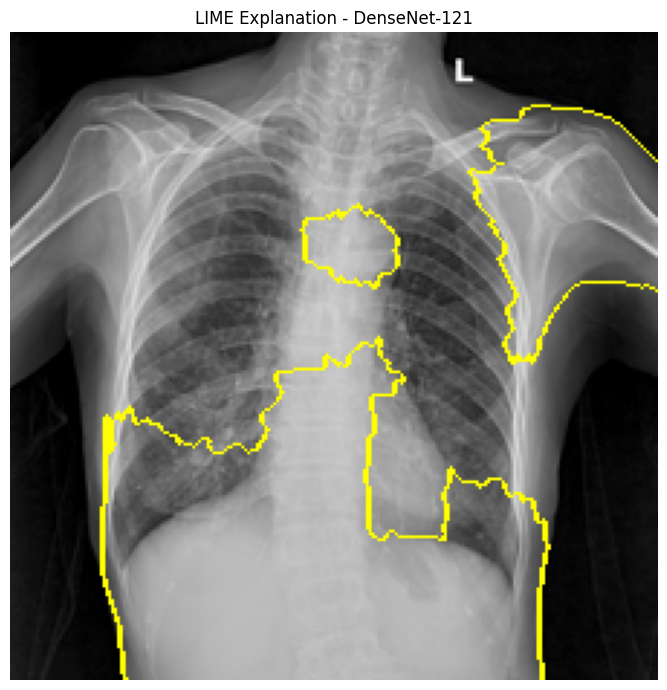

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

In [27]:
explainer = lime_image.LimeImageExplainer(random_state=42)

explanation = explainer.explain_instance(
    display_image,
    classifier_fn=predict,
    top_labels=2,
    hide_color=0,
    num_samples=1000
)

print("LIME explanation generated!")
predicted_class = int(np.argmax(predict(display_image[np.newaxis, ...])[0]))

image_explanation, mask = explanation.get_image_and_mask(
    label=predicted_class,
    positive_only=True,
    num_features=10,
    hide_rest=False
)

plt.figure(figsize=(7, 7))
from IPython.display import display

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(mark_boundaries(image_explanation, mask))
ax.set_title("LIME Explanation - DenseNet-121")
ax.axis("off")

plt.tight_layout()
display(fig)
plt.close(fig)

**Implementing Fairness with AIF360**

Fairness evaluation using AIF360 cannot be meaningfully implemented in the current Ray Verify dataset because it does not contain independent protected attributes, such as age, sex, or other demographic or acquisition-related groups. The available metadata fields (quality_status, provenance_evidence, and label_status) contain only one common value across the dataset. Although origin_label distinguishes patient-acquired and synthetic images, it is the target variable that DenseNet is trained to predict, not an independent protected attribute. Using it as a protected attribute would produce misleading fairness conclusions. Therefore, a valid group-fairness assessment requires additional, reliable subgroup metadata, which is currently unavailable.

**FGSM Adversarial Robustness Testing — DenseNet-121 Ensemble**

Goal is to test whether small, deliberately introduced changes to chest X-ray pixels can cause DenseNet to misclassify an image

In [28]:
import torch
import torch.nn.functional as F
import numpy as np

# ImageNet normalization values used by DenseNet
mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device
).view(1, 3, 1, 1)


# Average softmax probabilities from all five models
def densenet_ensemble_probabilities(images):

    model_probabilities = []

    for model in densenet_models:
        model.eval()

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        model_probabilities.append(probabilities)

    return torch.stack(model_probabilities).mean(dim=0)


print("DenseNet ensemble prediction function ready.")

DenseNet ensemble prediction function ready.


Defining attack

In [29]:
def fgsm_ensemble_attack(images, labels, epsilon=8/255):

    images = images.clone().detach().to(device)
    labels = labels.clone().detach().long().to(device)

    # Convert normalized images back to pixel values [0, 1]
    pixel_images = images * std + mean
    pixel_images = pixel_images.clamp(0, 1)

    # Enable gradients with respect to original pixels
    pixel_images.requires_grad = True

    # Normalize again before sending images to DenseNet
    normalized_images = (pixel_images - mean) / std

    # Obtain ensemble probabilities
    probabilities = densenet_ensemble_probabilities(
        normalized_images
    )

    # Untargeted FGSM: increase classification loss
    loss = F.nll_loss(
        torch.log(probabilities.clamp_min(1e-12)),
        labels
    )

    # Calculate gradients with respect to pixel values
    gradients = torch.autograd.grad(
        loss,
        pixel_images
    )[0]

    # Apply perturbation in original pixel space
    adversarial_pixels = (
        pixel_images + epsilon * gradients.sign()
    )

    # Keep pixel values within [0, 1]
    adversarial_pixels = adversarial_pixels.clamp(0, 1)

    # Normalize adversarial images for DenseNet
    adversarial_images = (
        adversarial_pixels - mean
    ) / std

    return adversarial_images.detach()


print("Pixel-space ensemble FGSM attack ready.")

Pixel-space ensemble FGSM attack ready.


Evaluate clean and adversarial predictions

In [30]:
epsilon = 8/255

clean_predictions = []
adversarial_predictions = []

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device).long()

    # Clean ensemble predictions
    with torch.no_grad():

        clean_probabilities = (
            densenet_ensemble_probabilities(images)
        )

        clean_pred = clean_probabilities.argmax(dim=1)

    # Generate adversarial images
    adversarial_images = fgsm_ensemble_attack(
        images,
        labels,
        epsilon=epsilon
    )

    # Adversarial ensemble predictions
    with torch.no_grad():

        adversarial_probabilities = (
            densenet_ensemble_probabilities(
                adversarial_images
            )
        )

        adversarial_pred = (
            adversarial_probabilities.argmax(dim=1)
        )

    clean_predictions.extend(
        clean_pred.cpu().numpy()
    )

    adversarial_predictions.extend(
        adversarial_pred.cpu().numpy()
    )


clean_predictions = np.asarray(clean_predictions)
adversarial_predictions = np.asarray(adversarial_predictions)

print("FGSM ensemble attack completed.")
print("Epsilon:", epsilon)
print("Number of attacked images:", len(adversarial_predictions))

FGSM ensemble attack completed.
Epsilon: 0.03137254901960784
Number of attacked images: 2521


Calculate attack performance

In [31]:
from sklearn.metrics import accuracy_score

clean_accuracy = accuracy_score(
    test_labels,
    clean_predictions
)

adversarial_accuracy = accuracy_score(
    test_labels,
    adversarial_predictions
)

accuracy_drop = clean_accuracy - adversarial_accuracy

print("DenseNet-121 Ensemble FGSM Results")
print(f"Clean accuracy: {clean_accuracy * 100:.2f}%")
print(f"Adversarial accuracy: {adversarial_accuracy * 100:.2f}%")
print(f"Accuracy drop: {accuracy_drop * 100:.2f} percentage points")
print(f"Epsilon: {epsilon:.6f}")

DenseNet-121 Ensemble FGSM Results
Clean accuracy: 98.73%
Adversarial accuracy: 42.40%
Accuracy drop: 56.33 percentage points
Epsilon: 0.031373
